# CNN for steel-surface inspection: NEU-CLS

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/neural-networks/05-neu-cls-cnn.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

This notebook reuses the CNN workflow from MNIST for an engineering
image-classification task. We predict one of six surface-defect labels
from a grayscale image of hot-rolled steel.

## What you will do

1. Make the external NEU-CLS images available locally and inspect labels.
2. Build a custom PyTorch `Dataset` and a stratified held-out split.
3. Define and train a compact CNN for the six defect categories.
4. Inspect learning curves, a confusion matrix, and confident mistakes.

## 1. Set up the NEU-CLS inspection task

The original six-class **NEU-CLS** dataset contains 1,800 grayscale images
of hot-rolled steel surfaces: 300 images each of crazing, inclusion,
patches, pitted surface, rolled-in scale, and scratches. Each original
image is $200 	imes 200$ pixels.

The image files are deliberately not committed to this repository. Download
the original archive from its
[official source](https://faculty.neu.edu.cn/songkc/en/zdylm/263270/list/index.htm),
extract it, and set `NEU_CLS_ROOT` below to the folder containing files such
as `Cr_1.bmp` and `Sc_1.bmp`. The default location is `data/NEU-CLS`.

| File prefix | Defect label |
|---|---|
| `Cr` | crazing |
| `In` | inclusion |
| `Pa` | patches |
| `PS` | pitted surface |
| `RS` | rolled-in scale |
| `Sc` | scratches |

In [1]:
import os
import random
from collections import Counter
from collections.abc import Callable
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch  # Tensors, automatic differentiation, and hardware support.
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split
from torch import nn  # Neural-network layers and loss functions.
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms


SEED = 4520
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 11})

# A PyTorch device specifies the hardware used to store tensors and run
# calculations. The model and its input tensors must be on the same device.
if torch.cuda.is_available():
    device = torch.device("cuda")  # Use an NVIDIA GPU when available.
elif torch.backends.mps.is_available():
    device = torch.device("mps")  # Use the GPU on an Apple Silicon Mac.
else:
    device = torch.device("cpu")  # Portable fallback; usually slower.

print(f"Using device: {device}")

Using device: mps


In [2]:
NEU_CLASS_NAMES = {
    "Cr": "crazing",
    "In": "inclusion",
    "Pa": "patches",
    "PS": "pitted surface",
    "RS": "rolled-in scale",
    "Sc": "scratches",
}
NEU_CLASS_PREFIXES = list(NEU_CLASS_NAMES)
NEU_CLS_ROOT = Path(os.environ.get("NEU_CLS_ROOT", "data/NEU-CLS"))
# Keep the notebook runnable even when the optional engineering images are absent.
HAS_NEU_CLS = NEU_CLS_ROOT.is_dir()


def label_from_neu_path(*, image_path: Path) -> int:
    """Convert an NEU-CLS file prefix into an integer class label.

    Args:
        image_path: Path such as `Cr_1.bmp` or `PS_300.bmp`.

    Returns:
        Integer label corresponding to the defect class.

    Raises:
        ValueError: If the image name does not use a recognized prefix.
    """
    prefix = image_path.stem.split("_", maxsplit=1)[0]
    if prefix not in NEU_CLASS_NAMES:
        raise ValueError(f"Unrecognized NEU-CLS image name: {image_path.name}")
    return NEU_CLASS_PREFIXES.index(prefix)


if HAS_NEU_CLS:
    neu_paths = sorted(NEU_CLS_ROOT.glob("*.bmp"))
    neu_labels = np.array(
        [label_from_neu_path(image_path=path) for path in neu_paths]
    )
    class_counts = Counter(neu_labels)
    print(f"NEU-CLS folder: {NEU_CLS_ROOT}")
    print(f"Images found:    {len(neu_paths):,}")
    for class_index, prefix in enumerate(NEU_CLASS_PREFIXES):
        print(f"  {NEU_CLASS_NAMES[prefix]:16s} {class_counts[class_index]:3d}")
else:
    print(
        "NEU-CLS images are not present yet. Download and extract the archive, "
        "then set NEU_CLS_ROOT to its image folder before continuing."
    )

NEU-CLS folder: /private/tmp/neu-cls/NEU-CLS
Images found:    1,800
  crazing          300
  inclusion        300
  patches          300
  pitted surface   300
  rolled-in scale  300
  scratches        300


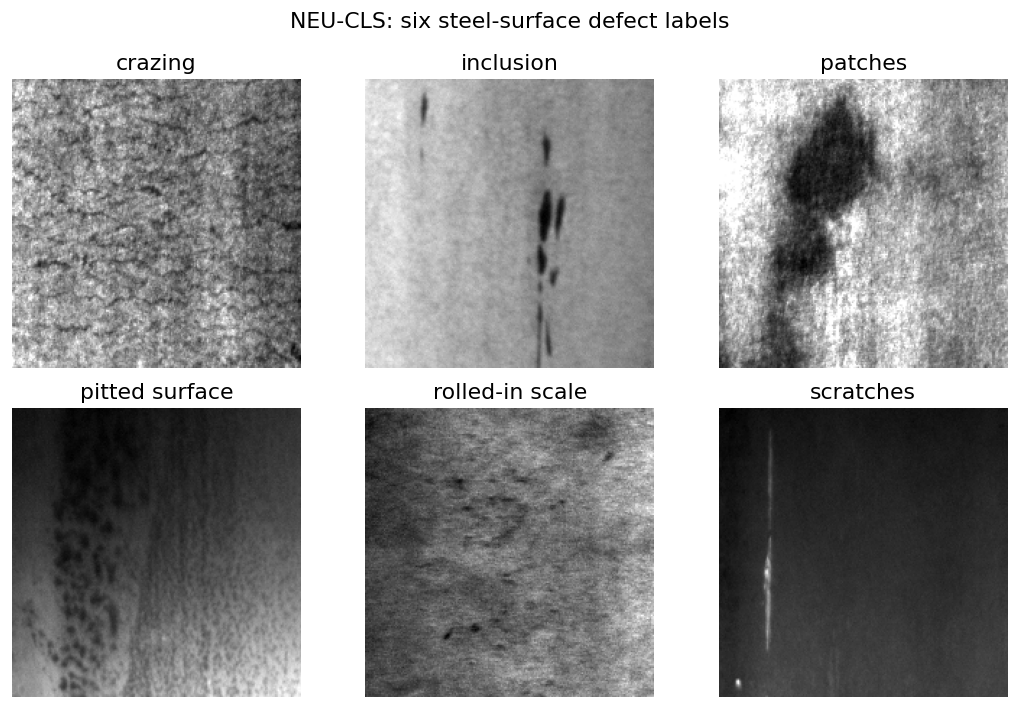

In [3]:
def show_neu_examples(*, image_paths: list[Path]) -> None:
    """Display one representative NEU-CLS image from each defect class.

    Args:
        image_paths: Paths to NEU-CLS bitmap images.
    """
    first_path_by_prefix: dict[str, Path] = {}
    for image_path in image_paths:
        prefix = image_path.stem.split("_", maxsplit=1)[0]
        first_path_by_prefix.setdefault(prefix, image_path)

    figure, axes = plt.subplots(2, 3, figsize=(9, 6))
    for axis, prefix in zip(axes.ravel(), NEU_CLASS_PREFIXES):
        with Image.open(first_path_by_prefix[prefix]) as image:
            axis.imshow(image, cmap="gray")
        axis.set_title(NEU_CLASS_NAMES[prefix])
        axis.axis("off")
    figure.suptitle("NEU-CLS: six steel-surface defect labels", y=0.98)
    figure.tight_layout()


if HAS_NEU_CLS:
    show_neu_examples(image_paths=neu_paths)

## 2. Make a stratified held-out split

We resize each image to $64 	imes 64$ and create a stratified 75/25
split. The split preserves the equal class counts in both sets. We use no
data augmentation for this first inspection model, so the data pipeline
stays transparent.

In [4]:
# Subclass Dataset so a DataLoader can request one `(image_tensor, label)` pair.
class NEUSurfaceDefectDataset(Dataset):
    """Load original NEU-CLS bitmap images for multi-class classification."""

    def __init__(
        self,
        *,
        image_paths: list[Path],
        labels: np.ndarray,
        transform: Callable[[Image.Image], torch.Tensor],
    ) -> None:
        """Store paths, labels, and the image transformation.

        Args:
            image_paths: Bitmap image paths in a fixed order.
            labels: Integer labels aligned with image paths.
            transform: Transformation from one PIL image to one tensor.
        """
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    # DataLoader uses `__len__` to know how many examples are available.
    def __len__(self) -> int:
        """Return the number of images in the dataset."""
        return len(self.image_paths)

    # DataLoader calls `__getitem__` to fetch one image and its integer label.
    def __getitem__(self, position: int) -> tuple[torch.Tensor, int]:
        """Load, transform, and label one steel-surface image.

        Args:
            position: Position of the image in this dataset split.

        Returns:
            A transformed grayscale image and its integer defect label.
        """
        with Image.open(self.image_paths[position]) as image:
            image_tensor = self.transform(image.convert("L"))
        return image_tensor, int(self.labels[position])


# Standardize every image's size and numerical scale before the CNN sees it.
steel_transform = transforms.Compose(
    [
        transforms.Resize(size=(64, 64)),  # All images share one spatial shape.
        transforms.ToTensor(),
        # Approximately map original [0, 1] pixels into [-1, 1].
        transforms.Normalize(mean=(0.5,), std=(0.5,)),
    ]
)

if HAS_NEU_CLS:
    # `stratify` keeps the six class proportions equal in both splits.
    train_paths, test_paths, train_labels, test_labels_steel = train_test_split(
        neu_paths,
        neu_labels,
        test_size=0.25,
        random_state=SEED,
        stratify=neu_labels,
    )
    steel_train = NEUSurfaceDefectDataset(
        image_paths=train_paths,
        labels=train_labels,
        transform=steel_transform,
    )
    steel_test = NEUSurfaceDefectDataset(
        image_paths=test_paths,
        labels=test_labels_steel,
        transform=steel_transform,
    )
    # Use shuffled mini-batches for training and a fixed order for testing.
    steel_train_loader = DataLoader(
        steel_train,
        batch_size=64,
        shuffle=True,
        num_workers=0,
    )
    steel_test_loader = DataLoader(
        steel_test,
        batch_size=64,
        shuffle=False,
        num_workers=0,
    )
    print(f"Training images: {len(steel_train):,}")
    print(f"Test images:     {len(steel_test):,}")

Training images: 1,350
Test images:     450


## 3. Define and train a steel-inspection CNN

The network uses the same ingredients as the MNIST CNN—convolutions,
ReLUs, pooling, and a final classifier—but predicts six defect classes
instead of ten digits. `AdaptiveAvgPool2d` turns the last feature maps into
a fixed $4 	imes 4$ grid before classification.

In [5]:
class SteelSurfaceCNN(nn.Module):
    """Classify 64-by-64 grayscale steel-surface images into six classes."""

    def __init__(self, *, n_classes: int = 6) -> None:
        """Initialize a compact CNN for the steel-inspection images.

        Args:
            n_classes: Number of output defect categories.
        """
        super().__init__()
        # This block turns an image into increasingly abstract feature maps.
        self.features = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.ReLU(),
            # Force a fixed 4-by-4 feature-map size before the classifier.
            nn.AdaptiveAvgPool2d(output_size=(4, 4)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=64 * 4 * 4, out_features=128),
            nn.ReLU(),
            # Dropout is active only in training and helps discourage overfitting.
            nn.Dropout(p=0.2),
            # Six logits: one unnormalized score for each defect category.
            nn.Linear(in_features=128, out_features=n_classes),
        )

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        """Return one logit for each steel-surface defect class.

        Args:
            images: Image batch with shape `(batch, 1, 64, 64)`.

        Returns:
            Logits with shape `(batch, n_classes)`.
        """
        return self.classifier(self.features(images))


def train_one_epoch(
    *,
    model: nn.Module,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    loss_function: nn.Module,
    device: torch.device,
) -> tuple[float, float]:
    """Train a model for one pass through a dataset.

    Args:
        model: CNN to train.
        loader: Mini-batches of images and integer labels.
        optimizer: Optimizer that applies parameter updates.
        loss_function: Loss evaluated from logits and labels.
        device: Device on which calculations are performed.

    Returns:
        Mean loss and classification accuracy across the dataset.
    """
    model.train()
    total_loss = 0.0
    correct_predictions = 0
    total_examples = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)
        # Clear stored gradients, then run forward pass, backpropagation, and update.
        optimizer.zero_grad()
        logits = model(images)
        loss = loss_function(logits, labels)
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        correct_predictions += (logits.argmax(dim=1) == labels).sum().item()
        total_examples += batch_size

    return total_loss / total_examples, correct_predictions / total_examples


def evaluate(
    *,
    model: nn.Module,
    loader: DataLoader,
    loss_function: nn.Module,
    device: torch.device,
) -> tuple[float, float, np.ndarray, np.ndarray, np.ndarray]:
    """Evaluate a model without changing its parameters.

    Args:
        model: CNN to evaluate.
        loader: Mini-batches of images and integer labels.
        loss_function: Loss evaluated from logits and labels.
        device: Device on which calculations are performed.

    Returns:
        Mean loss, accuracy, true labels, predicted labels, and probabilities.
    """
    model.eval()
    total_loss = 0.0
    correct_predictions = 0
    total_examples = 0
    all_labels: list[np.ndarray] = []
    all_predictions: list[np.ndarray] = []
    all_probabilities: list[np.ndarray] = []

    # Do not build a gradient graph during evaluation.
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            loss = loss_function(logits, labels)
            probabilities = torch.softmax(logits, dim=1)
            predictions = probabilities.argmax(dim=1)

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            correct_predictions += (predictions == labels).sum().item()
            total_examples += batch_size
            all_labels.append(labels.cpu().numpy())
            all_predictions.append(predictions.cpu().numpy())
            all_probabilities.append(probabilities.cpu().numpy())

    return (
        total_loss / total_examples,
        correct_predictions / total_examples,
        np.concatenate(all_labels),
        np.concatenate(all_predictions),
        np.concatenate(all_probabilities),
    )


if HAS_NEU_CLS:
    # Re-establish a fixed initialization and mini-batch order for this task.
    torch.manual_seed(SEED)
    steel_model = SteelSurfaceCNN().to(device)
    print(steel_model)
    print(f"Trainable parameters: {sum(parameter.numel() for parameter in steel_model.parameters()):,}")

SteelSurfaceCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=6, bias=True)
  )
)
Trainable parameters: 155,270


In [6]:
if HAS_NEU_CLS:
    STEEL_EPOCHS = 15
    # CrossEntropyLoss applies softmax internally; Adam updates parameters.
    steel_loss_function = nn.CrossEntropyLoss()
    steel_optimizer = torch.optim.Adam(
        params=steel_model.parameters(),
        lr=1e-3,
        weight_decay=1e-4,  # L2 regularization discourages large weights.
    )
    steel_history = {
        "train_loss": [],
        "train_accuracy": [],
        "test_loss": [],
        "test_accuracy": [],
    }

    for epoch in range(1, STEEL_EPOCHS + 1):
        steel_train_loss, steel_train_accuracy = train_one_epoch(
            model=steel_model,
            loader=steel_train_loader,
            optimizer=steel_optimizer,
            loss_function=steel_loss_function,
            device=device,
        )
        steel_test_loss, steel_test_accuracy, _, _, _ = evaluate(
            model=steel_model,
            loader=steel_test_loader,
            loss_function=steel_loss_function,
            device=device,
        )
        steel_history["train_loss"].append(steel_train_loss)
        steel_history["train_accuracy"].append(steel_train_accuracy)
        steel_history["test_loss"].append(steel_test_loss)
        steel_history["test_accuracy"].append(steel_test_accuracy)

        if epoch == 1 or epoch % 5 == 0 or epoch == STEEL_EPOCHS:
            print(
                f"Epoch {epoch:2d}: "
                f"train accuracy = {steel_train_accuracy:.3f}; "
                f"test accuracy = {steel_test_accuracy:.3f}"
            )

Epoch  1: train accuracy = 0.282; test accuracy = 0.298


Epoch  5: train accuracy = 0.609; test accuracy = 0.658


Epoch 10: train accuracy = 0.800; test accuracy = 0.829


Epoch 15: train accuracy = 0.893; test accuracy = 0.913


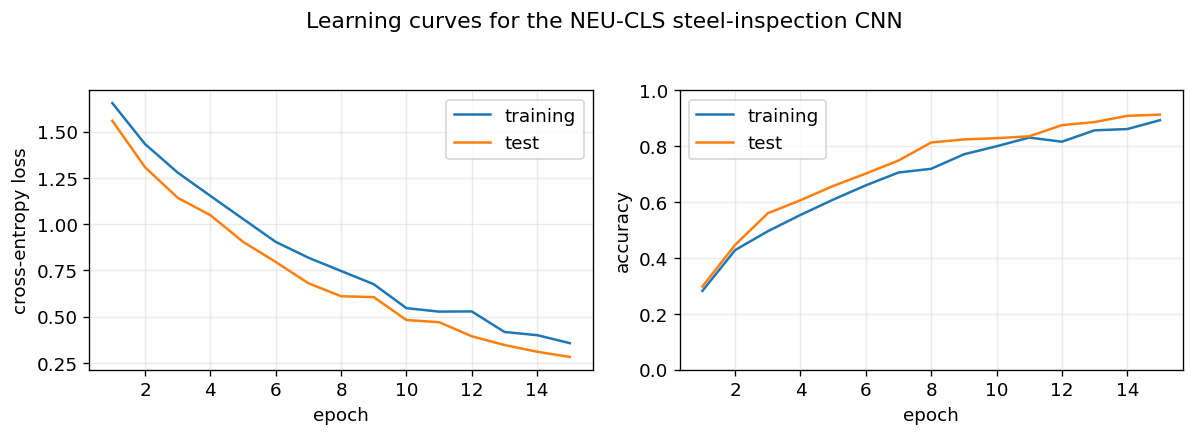

In [7]:
if HAS_NEU_CLS:
    steel_epochs = np.arange(1, STEEL_EPOCHS + 1)
    figure, axes = plt.subplots(1, 2, figsize=(10, 3.5))

    axes[0].plot(steel_epochs, steel_history["train_loss"], label="training")
    axes[0].plot(steel_epochs, steel_history["test_loss"], label="test")
    axes[0].set(xlabel="epoch", ylabel="cross-entropy loss")
    axes[0].legend()
    axes[0].grid(alpha=0.25)

    axes[1].plot(steel_epochs, steel_history["train_accuracy"], label="training")
    axes[1].plot(steel_epochs, steel_history["test_accuracy"], label="test")
    axes[1].set(xlabel="epoch", ylabel="accuracy", ylim=(0.0, 1.0))
    axes[1].legend()
    axes[1].grid(alpha=0.25)

    figure.suptitle("Learning curves for the NEU-CLS steel-inspection CNN", y=1.03)
    figure.tight_layout()

## 4. Inspect held-out performance and errors

The confusion matrix identifies defect labels that this small model finds
difficult to distinguish. The displayed errors are its most confident
mistakes—use them to ask what local texture may have been misleading.

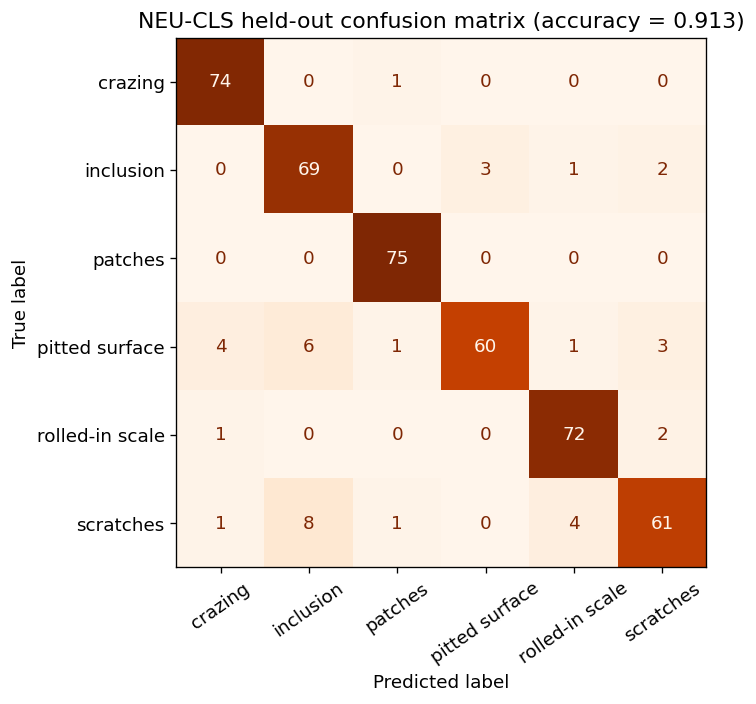

In [8]:
if HAS_NEU_CLS:
    (
        steel_test_loss,
        steel_test_accuracy,
        steel_test_labels,
        steel_test_predictions,
        steel_test_probabilities,
    ) = evaluate(
        model=steel_model,
        loader=steel_test_loader,
        loss_function=steel_loss_function,
        device=device,
    )

    figure, axis = plt.subplots(figsize=(7, 6))
    display = ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrix(steel_test_labels, steel_test_predictions),
        display_labels=[NEU_CLASS_NAMES[prefix] for prefix in NEU_CLASS_PREFIXES],
    )
    display.plot(ax=axis, cmap="Oranges", colorbar=False, xticks_rotation=35)
    axis.set_title(
        "NEU-CLS held-out confusion matrix "
        f"(accuracy = {steel_test_accuracy:.3f})"
    )
    figure.tight_layout()

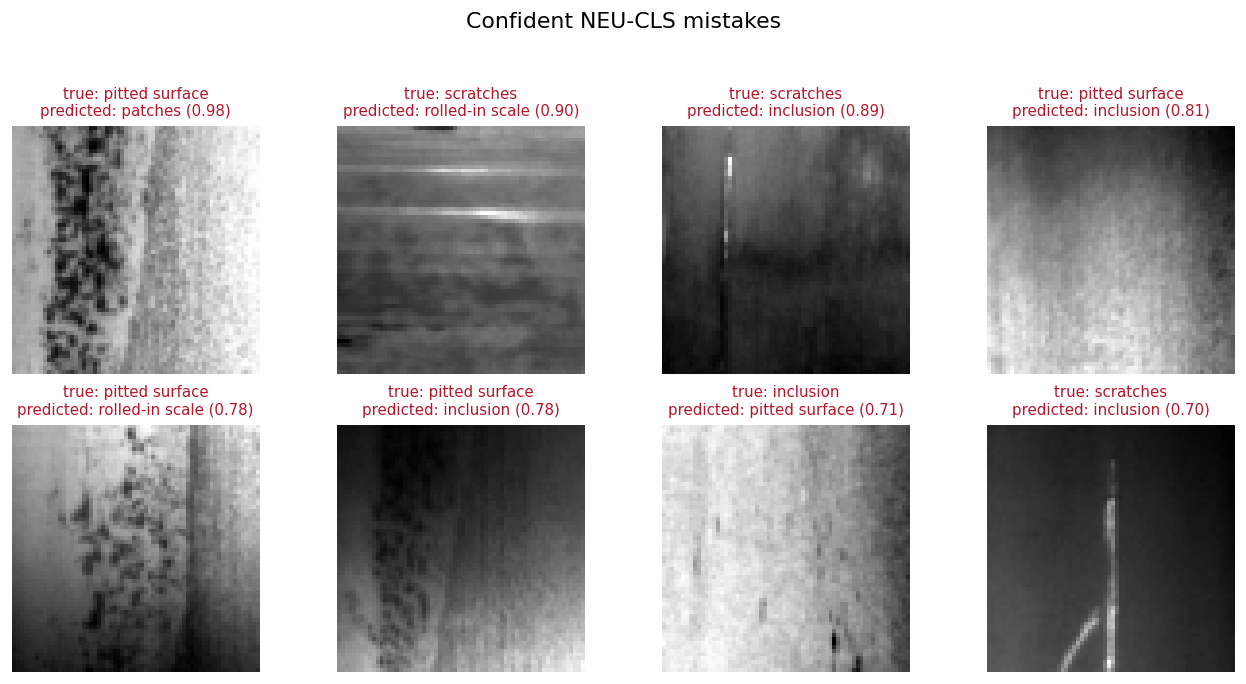

In [9]:
def show_misclassified_steel_images(
    *,
    dataset: NEUSurfaceDefectDataset,
    labels: np.ndarray,
    predictions: np.ndarray,
    probabilities: np.ndarray,
    n_examples: int = 8,
) -> None:
    """Display confidently wrong steel-surface predictions.

    Args:
        dataset: Held-out NEU-CLS dataset split.
        labels: True integer defect labels.
        predictions: Predicted integer defect labels.
        probabilities: Class probabilities for each image.
        n_examples: Maximum number of wrong predictions to display.
    """
    incorrect_positions = np.flatnonzero(labels != predictions)
    confidence = probabilities[incorrect_positions, predictions[incorrect_positions]]
    selected_positions = incorrect_positions[
        np.argsort(confidence)[-n_examples:]
    ][::-1]

    figure, axes = plt.subplots(2, 4, figsize=(11, 5.5))
    for axis, position in zip(axes.ravel(), selected_positions):
        image_tensor, _ = dataset[int(position)]
        confidence_value = probabilities[position, predictions[position]]
        axis.imshow(image_tensor.squeeze(), cmap="gray")
        axis.set_title(
            f"true: {NEU_CLASS_NAMES[NEU_CLASS_PREFIXES[labels[position]]]}\n"
            f"predicted: {NEU_CLASS_NAMES[NEU_CLASS_PREFIXES[predictions[position]]]} "
            f"({confidence_value:.2f})",
            color="#b2182b",
            fontsize=9,
        )
        axis.axis("off")
    for axis in axes.ravel()[len(selected_positions):]:
        axis.axis("off")
    figure.suptitle("Confident NEU-CLS mistakes", y=1.03)
    figure.tight_layout()


if HAS_NEU_CLS:
    show_misclassified_steel_images(
        dataset=steel_test,
        labels=steel_test_labels,
        predictions=steel_test_predictions,
        probabilities=steel_test_probabilities,
    )

## Takeaways

- The same PyTorch CNN workflow transfers from MNIST to steel-surface images.
- A custom `Dataset` adapts an external image collection to the standard
  `DataLoader` / model / loss / optimizer pipeline.
- This random split is an instructional benchmark, not a production
  deployment study. Images from a different line, camera, steel batch, or
  operating condition should be held separate when assessing generalization.

[← Return to Neural networks](http://localhost:4170/neural-networks/)